# 01 · La base de datos y las señales

**Pregunta de este notebook.** ¿Qué hay en la base Apnea-ECG, cómo se ven las señales y qué problemas tienen? De acá salen los requisitos del preprocesamiento (notebook `02`) y la idea que se pone a prueba en todo el trabajo.

**Hilo del trabajo.**
1. `01` — base de datos, etiquetas y exploración de las señales (este notebook).
2. `02` — filtro, latidos y serie RR.
3. `03` — latidos como realizaciones, filtro de Wiener y respiración derivada del ECG (EDR).
4. `04` — la feature, el umbral y la evaluación del detector.

**Hipótesis del trabajo.** Durante la apnea, la frecuencia cardíaca y la respiración oscilan juntas al ritmo del ciclo apnea–recuperación. Por eso, en los minutos con apnea, la potencia que comparten la serie RR y la EDR en la banda lenta (0,01–0,05 Hz) es mayor que en los minutos normales, y alcanza para clasificar cada minuto con un único umbral.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

from concurrent.futures import ProcessPoolExecutor

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.signal import spectrogram, welch

from src.config import SPLIT_CSV
from src.features.edr import compute_edr, qrs_reference
from src.data import (load_apnea_labels, load_ecg, load_ecg_digital, load_header, load_qrs,
                      load_record_info, load_respiration)
from src.preprocessing.quality import flat_mask, saturated_mask
from src.qrs.rr_clean import clean_rr
from src.viz.plots import (ANCHO, APNEA, COLORES_CAT, GRIS, NORMAL, label_strip, save, setup,
                           shade_apnea)

setup()
split = pd.read_csv(SPLIT_CSV)
info = load_record_info()
base = split.merge(info[["record", "AHI", "AI", "HI", "age", "sex", "height_cm", "weight_kg"]], on="record")
DEV = split[split.set == "dev"].record.tolist()
base = base[base.set == "dev"]          # durante el desarrollo solo se miran los registros de desarrollo

## 1. Qué es la base

La **Apnea-ECG Database** (Penzel et al., 2000; PhysioNet) se armó para el *PhysioNet/Computers in Cardiology Challenge 2000*. Tiene 70 registros nocturnos de 7 a 10 horas con:

- **ECG de una derivación**, muestreado a **100 Hz** con un conversor de 12 bits.
- **Una etiqueta por minuto** (apnea o normal), asignada por un experto mirando la respiración y la saturación de oxígeno de la polisomnografía. Un minuto se marca como apnea si en él hay una apnea o una hipopnea.
- En 8 registros (a01–a04, b01, c01–c03), además, la **respiración** medida (bandas de tórax y abdomen, flujo nasal y SpO2). La usamos solo para validar la respiración derivada del ECG.
- Edad, sexo, altura, peso y el índice de apnea-hipopnea (AHI) de cada registro.

### Las categorías A, B y C

PhysioNet agrupa los registros según cuánta apnea tienen. La categoría **no** describe a la persona sino a la noche:

| Categoría | Criterio de PhysioNet |
|---|---|
| **A** (apnea) | al menos una hora con índice de apnea ≥ 10 **y** al menos 100 minutos con apnea en la noche |
| **B** (límite) | al menos una hora con índice de apnea ≥ 5 **y** entre 5 y 99 minutos con apnea |
| **C** (control) | menos de 5 minutos con apnea |

La figura muestra la regla con los 47 registros de desarrollo: el eje horizontal es la cantidad de minutos con apnea de cada noche y el vertical, el AHI. (Durante el desarrollo **no se mira ningún dato de test**: de test solo se usa, en la sección 2, la tabla con la que se verifica la partición.)

,registros,AHI_mediana,AHI_min,AHI_max,pct_apnea_mediana
category,,,,,
A,28,42.5,14.30,82.40,62.2
B,7,19.0,0.13,33.00,12.6
C,12,0.0,0.00,0.38,0.2


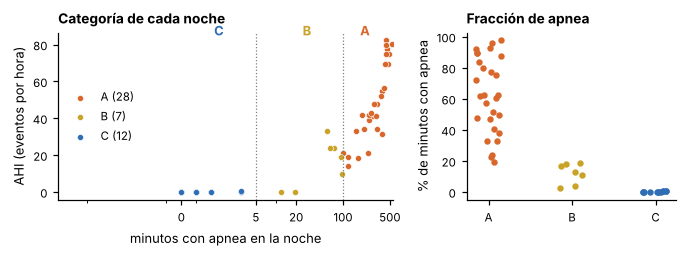

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(ANCHO, 2.4), gridspec_kw={"width_ratios": [1.6, 1]})
for cat, g in base.groupby("category"):
    ax[0].scatter(g.apnea_minutes, g.AHI, s=16, color=COLORES_CAT[cat], label=f"{cat} ({len(g)})",
                  edgecolor="white", lw=0.4)
for x in (5, 100):
    ax[0].axvline(x, color=GRIS, ls=":", lw=0.8)
ax[0].set_xscale("symlog", linthresh=5)
ax[0].set_xticks([0, 5, 20, 100, 500]); ax[0].set_xticklabels([0, 5, 20, 100, 500])
ax[0].set(xlabel="minutos con apnea en la noche", ylabel="AHI (eventos por hora)",
          title="Categoría de cada noche")
ax[0].text(2.2, 85, "C", color=COLORES_CAT["C"], fontweight="bold")
ax[0].text(25, 85, "B", color=COLORES_CAT["B"], fontweight="bold")
ax[0].text(180, 85, "A", color=COLORES_CAT["A"], fontweight="bold")
ax[0].legend(loc="center left")
frac = base.assign(f=base.apnea_minutes / base.n_minutes)
for i, cat in enumerate("ABC"):
    v = frac.loc[frac.category == cat, "f"]
    ax[1].scatter(np.full(len(v), i) + np.random.default_rng(0).uniform(-0.15, 0.15, len(v)), 100 * v,
                  s=10, color=COLORES_CAT[cat])
ax[1].set_xticks([0, 1, 2]); ax[1].set_xticklabels(["A", "B", "C"])
ax[1].set(ylabel="% de minutos con apnea", title="Fracción de apnea")
fig.tight_layout()
save(fig, "01_categorias")
(frac.groupby("category").agg(registros=("record", "size"), AHI_mediana=("AHI", "median"),
                              AHI_min=("AHI", "min"), AHI_max=("AHI", "max"),
                              pct_apnea_mediana=("f", lambda v: round(100 * v.median(), 1))))

**Qué se ve.** Las tres categorías quedan separadas por los cortes de 5 y 100 minutos. En las noches A la mayoría de los minutos tienen apnea; en las C, casi ninguno. Eso hace que en la base haya **noches enteras de apnea y noches enteras normales**, algo a tener en cuenta al evaluar: un detector que solo reconozca a la persona (y no al minuto) parecería funcionar bien.

## 2. Registros, sujetos y partición

Antes de mirar las señales se separan los registros en **desarrollo** (donde se toman todas las decisiones) y **test** (donde se mide el detector terminado, una sola vez). Cómo se parte determina si el resultado de test es creíble, así que cada decisión se justifica y se verifica.

**Qué información se usa.** La partición se armó solo con datos de cada registro: el perfil de la persona (edad, sexo, altura, peso), la categoría y la cantidad de minutos con apnea. Para verificarla se usa esa misma información. Las comprobaciones que miran señales (el latido de cada registro) se hacen solo con desarrollo y con los registros excluidos.

| # | Decisión | Por qué |
|---|---|---|
| 1 | Excluir una grabación de cada par duplicado | Una misma señal en desarrollo y en test sería evaluar con datos ya vistos |
| 2 | Agrupar los registros por persona | La base no identifica a las personas, pero hay noches distintas de la misma persona |
| 3 | Partir por persona, no por registro ni por minuto | Las noches de una persona se parecen; si estuviera en los dos conjuntos, test no mediría generalización |
| 4 | 70 % desarrollo, 30 % test | Equilibrio entre tener sujetos para decidir y sujetos para evaluar |
| 5 | Las mismas proporciones de A, B y C en los dos conjuntos | El detector se evalúa también por noche y por categoría |
| 6 | La misma fracción de minutos con apnea (± 2 puntos) | Exactitud, VPP y el umbral dependen de cuánta apnea hay |
| 7 | Los registros con respiración, en desarrollo | Son los únicos con los que se puede validar la EDR |
| 8 | Sorteo con semilla entre todas las particiones que cumplen 1–7 | Nadie elige qué sujetos van a test |

In [3]:
from itertools import combinations

from src.config import EXCLUDED, SAME_RECORDING
from src.duplicates import PRE, POST, beat_template, signal_match, template_similarity
from src.split import PROFILE, assign_subjects, candidate_splits

### Decisión 1: grabaciones duplicadas

Comparando el latido promedio de todos los pares de registros y buscando después un tramo de 5 minutos de uno dentro del otro (`src/duplicates.py`) aparecen tres pares que son **la misma grabación** con unos segundos de desfase. PhysioNet documenta solo el primero. Se excluye de cada par la grabación que empieza más tarde.

,correlación de la señal,desfase (s),minutos de apnea,se excluye
par,,,,
c05 = c06,1.0,80.0,3 / 1,c05
x22 = x35,1.0,40.0,2 / 0,x22
x33 = x34,1.0,70.0,3 / 4,x33


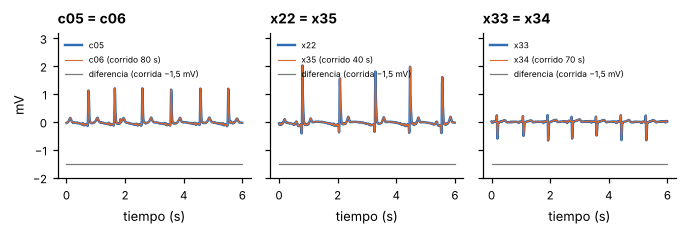

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(ANCHO, 2.2), sharey=True)
filas_dup = []
for ax, (a, b) in zip(axes, SAME_RECORDING):
    xa, fs_ = load_ecg(a); xb, _ = load_ecg(b)
    lag, r_ = signal_match(xa, xb, fs_)
    i0, n = int(120 * 60 * fs_), int(6 * fs_)
    t = np.arange(n) / fs_
    sa, sb = xa[i0:i0 + n], xb[i0 + lag:i0 + lag + n]
    ax.plot(t, sa, color=NORMAL, lw=1.6, label=a)
    ax.plot(t, sb, color=APNEA, lw=0.7, label=f"{b} (corrido {abs(lag) / fs_:.0f} s)")
    ax.plot(t, sa - sb - 1.5, color=GRIS, lw=0.8, label="diferencia (corrida −1,5 mV)")
    ax.set(title=f"{a} = {b}", xlabel="tiempo (s)", ylim=(-2, 3.2))
    ax.legend(loc="upper left", fontsize=5.5, ncol=1)
    la, lb = load_apnea_labels(a), load_apnea_labels(b)
    filas_dup.append({"par": f"{a} = {b}", "correlación de la señal": round(r_, 4),
                      "desfase (s)": abs(lag) / fs_, "minutos de apnea": f"{int((la == 1).sum())} / {int((lb == 1).sum())}",
                      "se excluye": [k for k in (a, b) if k in EXCLUDED][0]})
axes[0].set_ylabel("mV")
fig.tight_layout()
save(fig, "01_duplicados")
pd.DataFrame(filas_dup).set_index("par")

**Qué se ve.** Una vez alineadas, las dos señales de cada par coinciden muestra a muestra (la diferencia es cero). Las etiquetas de apnea de una misma grabación difieren en algunos minutos: es una medida concreta del **ruido de las etiquetas** (limitación 3 de `docs/objetivos_hipotesis.md`). Quedan **67 registros**.

### Decisión 2: agrupar los registros por persona

La base no dice qué registros son de la misma persona, pero muchos registros tienen **exactamente el mismo perfil** (edad, sexo, altura y peso). ¿Puede ser casualidad? Se mezclan las cuatro columnas por separado (se conserva cuántas veces aparece cada edad, cada altura, etc., pero se rompe la relación entre ellas) y se cuenta cuántos pares de registros quedan con el perfil idéntico.

pares con perfil idéntico: 52 · por azar: mediana 0, máximo 3 en 10.000 mezclas
pares con el latido casi idéntico (|r| > 0,95): misma persona 46 % de 41 pares · distinta persona 2 % de 1040 pares


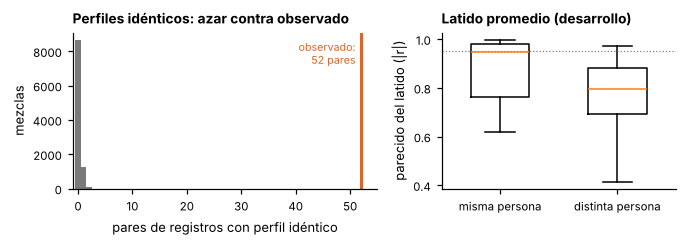

In [5]:
info_all = load_record_info()
codes = np.column_stack([pd.factorize(info_all[c])[0] for c in PROFILE]).astype(np.int64)
base_c = codes.max(axis=0) + 1

def pares_iguales(c):
    key = ((c[:, 0] * base_c[1] + c[:, 1]) * base_c[2] + c[:, 2]) * base_c[3] + c[:, 3]
    _, n = np.unique(key, return_counts=True)
    return int((n * (n - 1) // 2).sum())

rng_p = np.random.default_rng(2026)
obs = pares_iguales(codes)
nulo = np.array([pares_iguales(np.column_stack([rng_p.permutation(codes[:, j]) for j in range(4)]))
                 for _ in range(10_000)])

# El latido promedio funciona como huella de la persona (anatomía, posición de los electrodos).
subj = assign_subjects(info_all)
T = {}
for r in DEV:
    ecg_r, fs_r = load_ecg(r)
    T[r] = beat_template(ecg_r, load_qrs(r), fs_r)
# Parecido sin importar la polaridad: en algunas noches los electrodos se colocaron al revés.
parecido = lambda a, b: max(template_similarity(T[a], T[b]), template_similarity(T[a], -T[b]))
pares = [(a, b, parecido(a, b), subj[a] == subj[b]) for a, b in combinations(DEV, 2)]
sim = pd.DataFrame(pares, columns=["a", "b", "r", "mismo"])

fig, ax = plt.subplots(1, 2, figsize=(ANCHO, 2.3), gridspec_kw={"width_ratios": [1.3, 1]})
ax[0].hist(nulo, bins=np.arange(-0.5, nulo.max() + 1.5), color=GRIS)
ax[0].axvline(obs, color=APNEA, lw=2)
ax[0].text(obs - 1, ax[0].get_ylim()[1] * 0.8, f"observado:\n{obs} pares", ha="right", fontsize=7, color=APNEA)
ax[0].set(xlim=(-1, obs + 3), xlabel="pares de registros con perfil idéntico", ylabel="mezclas",
          title="Perfiles idénticos: azar contra observado")
ax[1].boxplot([sim.r[sim.mismo], sim.r[~sim.mismo]], widths=0.5, showfliers=False)
ax[1].set_xticks([1, 2]); ax[1].set_xticklabels(["misma persona", "distinta persona"])
ax[1].axhline(0.95, color=GRIS, ls=":", lw=0.8)
ax[1].set(ylabel="parecido del latido (|r|)", title="Latido promedio (desarrollo)")
fig.tight_layout()
save(fig, "01_sujetos")
print(f"pares con perfil idéntico: {obs} · por azar: mediana {np.median(nulo):.0f}, máximo {nulo.max()} en 10.000 mezclas")
print(f"pares con el latido casi idéntico (|r| > 0,95): misma persona {100 * (sim.r[sim.mismo] > 0.95).mean():.0f} % "
      f"de {int(sim.mismo.sum())} pares · distinta persona {100 * (sim.r[~sim.mismo] > 0.95).mean():.0f} % de {int((~sim.mismo).sum())} pares")

**Qué se ve.** Por azar aparecen como mucho unos pocos pares con el perfil idéntico; en la base hay muchos más: **son noches distintas de una misma persona**. El latido lo confirma: en el 46 % de los pares de la misma persona el latido es casi idéntico (|r| > 0,95), contra el 2 % entre personas distintas. En otros pares de la misma persona el latido es distinto: los electrodos no quedaron en el mismo lugar cada noche, y por eso el parecido se mide sin importar la polaridad. Se agrupan los registros con el mismo perfil o que son la misma grabación (`src/split.py`, `assign_subjects`): **67 registros de 29 personas**. Ante la duda conviene agrupar de más: juntar a dos personas solo cuesta algo de balance; separar a una misma persona en los dos conjuntos filtra información a test.

### Decisión 3: partir por persona

Si se partiera por registro o por minuto, una misma persona podría quedar en los dos conjuntos. ¿Importa? Sí, si las noches de una persona se parecen entre sí. Se compara, en desarrollo, la fracción de apnea de dos noches de la misma persona con la de dos noches de personas distintas.

In [6]:
frac_dev = split[split.set == "dev"].assign(f=lambda d: 100 * d.apnea_minutes / d.n_minutes).set_index("record")
dif_mismo = np.array([abs(frac_dev.f[a] - frac_dev.f[b]) for a, b in combinations(DEV, 2) if subj[a] == subj[b]])
dif_otro = np.array([abs(frac_dev.f[a] - frac_dev.f[b]) for a, b in combinations(DEV, 2) if subj[a] != subj[b]])
Mi = {r: max(((parecido(r, o), o) for o in DEV if o != r)) for r in DEV}
con_grupo = [r for r in DEV if sum(subj[o] == subj[r] for o in DEV) > 1]   # tienen otra noche de su persona
acierta = sum(subj[Mi[r][1]] == subj[r] for r in con_grupo)
azar = sum((sum(subj[o] == subj[r] for o in DEV) - 1) / (len(DEV) - 1) for r in con_grupo)   # esperado si se elige otro registro al azar
print(f"diferencia de % de apnea entre dos noches (mediana): misma persona {np.median(dif_mismo):.1f} puntos "
      f"({len(dif_mismo)} pares) · distinta persona {np.median(dif_otro):.1f} puntos ({len(dif_otro)} pares)")
print(f"registro cuyo latido más parecido es de la misma persona: {acierta} de {len(con_grupo)} "
      f"(de los registros de desarrollo que tienen otra noche de su persona); por azar se esperarían {azar:.1f}")

diferencia de % de apnea entre dos noches (mediana): misma persona 7.0 puntos (41 pares) · distinta persona 37.5 puntos (1040 pares)
registro cuyo latido más parecido es de la misma persona: 32 de 46 (de los registros de desarrollo que tienen otra noche de su persona); por azar se esperarían 1.8


Dos noches de la misma persona tienen una cantidad de apnea mucho más parecida que dos noches de personas distintas (7 contra 37 puntos de diferencia), y el latido permite reconocer a la persona: en 32 de 46 registros, el latido más parecido es el de otra noche de la misma persona, cuando por azar serían unos 2. Si una persona estuviera en desarrollo y en test, el umbral se ajustaría con sus propias noches y el resultado de test sería optimista. Por eso **todos los registros de una persona van al mismo conjunto**, y por la misma razón más adelante los intervalos de confianza se calculan remuestreando personas, no minutos.

### Decisiones 4 a 8: proporción, cuotas, balance, respiración y sorteo

- **70/30 (decisión 4).** Con 29 personas no hay muchas opciones: test tiene que tener personas de las tres categorías, y desarrollo necesita suficientes para decidir (entre ellas, las de los 8 registros con respiración). Con 30 % quedan 20 registros de 10 personas en test y 47 de 19 en desarrollo.
- **Cuotas por categoría (decisión 5).** Test lleva exactamente el 30 % de los registros de cada categoría (redondeado). En los registros `x` la categoría no viene en el nombre y se calcula con los minutos de apnea (A: 100 o más; B: 5 a 99; C: menos de 5). Esa regla se verificó en los 34 registros `a`, `b`, `c` (sin `c05`, excluido), donde la categoría sí está en el nombre: coincide en todos (abajo).
- **Balance de apnea (decisión 6).** La fracción de minutos con apnea de test no se aparta más de 2 puntos de la de desarrollo. La exactitud y el valor predictivo positivo dependen de cuánta apnea hay, y el umbral se elige en desarrollo: si test tuviera otra proporción, su resultado no sería comparable.
- **Respiración en desarrollo (decisión 7).** Los 8 registros con respiración (de 8 personas distintas) son los únicos donde se puede comparar la EDR con la respiración medida. Costo: esa validación no se repite en test (limitación 7).
- **Sorteo (decisión 8).** Se enumeran **todas** las particiones que cumplen las condiciones y se elige una al azar con la semilla 2026, fijada antes de sortear. Así nadie elige qué personas quedan en test.

In [7]:
pool, masks = candidate_splits(split)
reglas = split[split.record.str[0] != "x"]
print(f"particiones posibles que cumplen las condiciones: {len(masks)} (de 2^{len(pool)} = {2 ** len(pool):,} "
      f"formas de repartir las {len(pool)} personas sorteables); se eligió una con semilla 2026")
print(f"regla de categoría por minutos = categoría del nombre en {int((reglas.category == reglas.rule_category).sum())} "
      f"de {len(reglas)} registros a/b/c")
print("personas en los dos conjuntos:", int((split.groupby("subject").set.nunique() > 1).sum()))
perfil = split.merge(info_all[["record", "age", "sex", "height_cm", "weight_kg"]], on="record")
perfil["IMC"] = perfil.weight_kg / (perfil.height_cm / 100) ** 2
verif = pd.DataFrame({
    "registros": split.groupby("set").size(),
    "personas": split.groupby("set").subject.nunique(),
    "A": split[split.category == "A"].groupby("set").size(),
    "B": split[split.category == "B"].groupby("set").size(),
    "C": split[split.category == "C"].groupby("set").size(),
    "% minutos con apnea": (100 * split.groupby("set").apnea_minutes.sum() / split.groupby("set").n_minutes.sum()).round(1),
    "edad (mediana)": perfil.drop_duplicates("subject").groupby("set").age.median(),
    "% hombres": (100 * perfil.drop_duplicates("subject").assign(h=lambda d: d.sex == "M").groupby("set").h.mean()).round(0),
    "IMC (mediana)": perfil.drop_duplicates("subject").groupby("set").IMC.median().round(1),
})
verif

particiones posibles que cumplen las condiciones: 853 (de 2^21 = 2,097,152 formas de repartir las 21 personas sorteables); se eligió una con semilla 2026
regla de categoría por minutos = categoría del nombre en 34 de 34 registros a/b/c
personas en los dos conjuntos: 0


,registros,personas,A,B,C,% minutos con apnea,edad (mediana),% hombres,IMC (mediana)
set,,,,,,,,,
dev,47,19,28,7,12,39.8,44.0,89.0,27.4
test,20,10,12,3,5,39.3,45.0,80.0,31.2


**Verificación.** Ninguna persona quedó en los dos conjuntos; las cuotas de categoría se cumplen exactamente (12, 3 y 5 en test) y la fracción de minutos con apnea difiere en medio punto. Edad, sexo e índice de masa corporal (IMC) no se usaron para partir; se muestran para ver si los conjuntos quedaron parecidos por azar. La edad sí; en test hay algo menos de hombres (8 de 10 personas contra 17 de 19) y el IMC es mayor (31 contra 27). Con 10 personas en test no se podía controlar todo, y la obesidad se asocia a más apnea: es una diferencia a tener en cuenta al interpretar test. Lo único de test que se mira en todo el desarrollo es esta tabla.

**Qué se usa de cada conjunto.** En **desarrollo** (47 registros, 19 personas) se miran las señales, se diseña el preprocesamiento y se elige el umbral. **Test** (20 registros, 10 personas) no se toca durante el desarrollo: se usa una sola vez, al final, para medir el detector terminado. Todo lo que sigue usa solo desarrollo.

## 3. Las etiquetas

Antes de mirar las señales conviene entender **qué hay que detectar**: cuántos minutos con apnea hay, cómo se agrupan y dónde caen en la noche. Eso define a qué nivel se evalúa y qué tan largo puede ser el tramo de señal que se mira para decidir un minuto.

minutos con etiqueta                                        23138.0
% de minutos con apnea                                         39.8
registros con 10–90 % de apnea (los dos tipos de minuto)       29.0
episodios de apnea                                            460.0
duración mediana de un episodio (min)                           6.0
% de episodios de un solo minuto                               22.4
% de episodios de 4 minutos o más                              61.3
dtype: float64

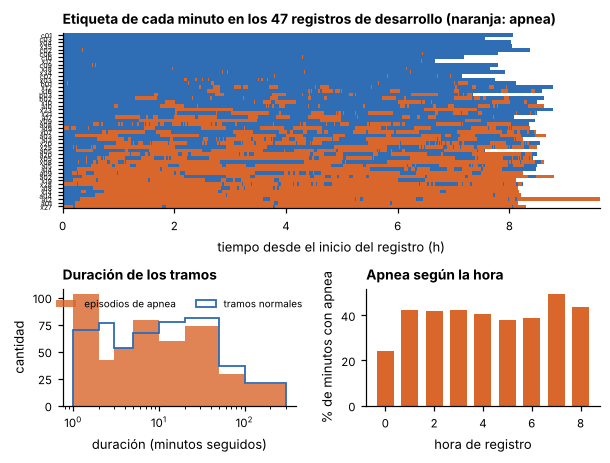

In [8]:
etiq = {rec: load_apnea_labels(rec) for rec in DEV}
orden_rec = sorted(DEV, key=lambda r: (etiq[r][etiq[r] >= 0].mean(), r))
largo = max(len(v) for v in etiq.values())
mapa = np.full((len(DEV), largo), np.nan)
for i, rec in enumerate(orden_rec):
    v = etiq[rec].astype(float); v[v < 0] = np.nan
    mapa[i, :len(v)] = v

rachas = {0: [], 1: []}
for v in etiq.values():
    v = v[v >= 0]
    b = np.flatnonzero(np.diff(np.r_[-9, v, -9]) != 0)
    for a_, e_ in zip(b[:-1], b[1:]):
        rachas[int(v[a_])].append(e_ - a_)
por_hora = pd.concat([pd.DataFrame({"hora": np.arange(len(v)) // 60, "apnea": v}) for v in etiq.values()])
por_hora = por_hora[por_hora.apnea >= 0].groupby("hora").apnea.agg(["mean", "size"])
por_hora = por_hora[por_hora["size"] >= 300]           # horas con datos de al menos 5 registros

fig = plt.figure(figsize=(ANCHO, 4.4))
gs = fig.add_gridspec(2, 2, height_ratios=[1.5, 1], hspace=0.55, wspace=0.3)
ax0 = fig.add_subplot(gs[0, :])
ax0.imshow(mapa, aspect="auto", interpolation="nearest", extent=[0, largo / 60, len(DEV), 0],
           cmap=plt.matplotlib.colors.ListedColormap([NORMAL, APNEA]), vmin=0, vmax=1)
ax0.set_yticks(np.arange(len(DEV)) + 0.5); ax0.set_yticklabels(orden_rec, fontsize=4.5)
ax0.set(xlabel="tiempo desde el inicio del registro (h)",
        title="Etiqueta de cada minuto en los 47 registros de desarrollo (naranja: apnea)")
ax1 = fig.add_subplot(gs[1, 0])
bins_r = np.r_[1, 2, 3, 5, 10, 20, 50, 100, 300]
ax1.hist(rachas[1], bins=bins_r, color=APNEA, alpha=0.8, label="episodios de apnea")
ax1.hist(rachas[0], bins=bins_r, color=NORMAL, histtype="step", lw=1.2, label="tramos normales")
ax1.set(xscale="log", xlabel="duración (minutos seguidos)", ylabel="cantidad", title="Duración de los tramos")
ax1.legend(loc="upper center", bbox_to_anchor=(0.5, 1.0), fontsize=6.5, ncol=2)
ax2 = fig.add_subplot(gs[1, 1])
ax2.bar(por_hora.index, 100 * por_hora["mean"], color=APNEA, width=0.7)
ax2.set(xlabel="hora de registro", ylabel="% de minutos con apnea", title="Apnea según la hora")
save(fig, "01_etiquetas")
r1 = np.array(rachas[1])
pd.Series({
    "minutos con etiqueta": int(sum((v >= 0).sum() for v in etiq.values())),
    "% de minutos con apnea": round(100 * sum((v == 1).sum() for v in etiq.values()) / sum((v >= 0).sum() for v in etiq.values()), 1),
    "registros con 10–90 % de apnea (los dos tipos de minuto)": sum(0.1 <= v[v >= 0].mean() <= 0.9 for v in etiq.values()),
    "episodios de apnea": len(r1),
    "duración mediana de un episodio (min)": float(np.median(r1)),
    "% de episodios de un solo minuto": round(100 * np.mean(r1 == 1), 1),
    "% de episodios de 4 minutos o más": round(100 * np.mean(r1 >= 4), 1),
})

apnea
los dos tipos (10–90 %)     29
casi sin apnea (< 10 %)     14
casi todo apnea (> 90 %)     4
Name: count, dtype: int64

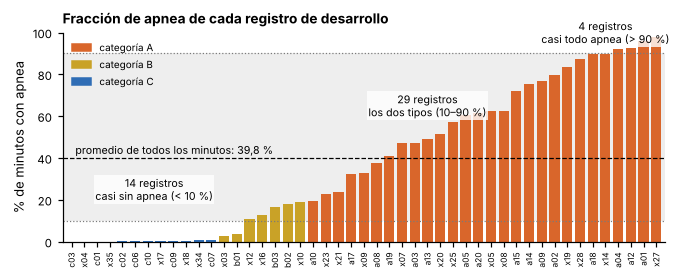

In [9]:
fr = pd.DataFrame({"record": DEV, "apnea": [100 * etiq[r][etiq[r] >= 0].mean() for r in DEV]})
fr = fr.merge(split[["record", "category"]]).sort_values("apnea").reset_index(drop=True)
zona = pd.cut(fr.apnea, [-1, 10, 90, 101], labels=["casi sin apnea (< 10 %)", "los dos tipos (10–90 %)",
                                                    "casi todo apnea (> 90 %)"])
fig, ax = plt.subplots(figsize=(ANCHO, 2.6))
ax.axhspan(10, 90, color=GRIS, alpha=0.12, lw=0)
ax.bar(np.arange(len(fr)), fr.apnea, color=fr.category.map(COLORES_CAT), width=0.8)
for y in (10, 90):
    ax.axhline(y, color=GRIS, ls=":", lw=0.8)
ax.axhline(100 * sum((v == 1).sum() for v in etiq.values()) / sum((v >= 0).sum() for v in etiq.values()),
           color="black", lw=0.8, ls="--")
ax.text(0.3, 42, "promedio de todos los minutos: 39,8 %", fontsize=7)
ax.set_xticks(np.arange(len(fr))); ax.set_xticklabels(fr.record, rotation=90, fontsize=5.5)
ax.set(ylabel="% de minutos con apnea", ylim=(0, 100), xlim=(-0.7, len(fr) - 0.3),
       title="Fracción de apnea de cada registro de desarrollo")
cuenta = zona.value_counts()
x_zona = {z: fr.index[zona == z].to_numpy().mean() for z in zona.cat.categories}
for z, y in zip(zona.cat.categories, (50, 50, 50)):
    if cuenta[z]:
        ax.text(x_zona[z] - (2.5 if z.startswith("casi todo") else 0),
                95 if z.startswith("casi todo") else (60 if z.startswith("los dos") else 20),
                f"{cuenta[z]} registros\n{z}", ha="center", fontsize=7,
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=1))
ax.legend(handles=[plt.matplotlib.patches.Patch(color=COLORES_CAT[c], label=f"categoría {c}") for c in "ABC"],
          loc="upper left", fontsize=6.5)
fig.tight_layout()
save(fig, "01_fraccion_apnea")
cuenta

**Qué se ve.**
- **Hay noches casi enteras de apnea y noches casi sin apnea** (segunda figura): 14 registros tienen menos del 10 % de minutos con apnea (los 12 controles y dos B) y 4 noches A tienen más del 90 %. Los otros **29 de los 47 registros**, en la franja gris, tienen los dos tipos de minuto en proporciones importantes. En esos 29 se puede medir si el detector separa los minutos con apnea de los normales **dentro de una misma noche**, sin que influya cuánta apnea tiene cada persona. Un detector podría parecer bueno solo por distinguir a las personas con mucha apnea de las que no tienen. Por eso, además del acierto con todos los minutos juntos, en `04` se mide **dentro de cada noche**, en esos 29 registros.
- **Los minutos con apnea vienen en tramos**: un episodio dura una mediana de 6 minutos, y solo uno de cada cinco es de un minuto aislado. Dos minutos seguidos se parecen mucho, así que **los minutos no son independientes**: la incertidumbre se calcula por sujeto, no por minuto. Y como la mayoría de los episodios dura varios minutos, mirar una ventana de algunos minutos alrededor de cada minuto no borra la mayoría de los episodios.
- **En la primera hora hay menos apnea** (~25 % contra ~40 % el resto de la noche): al principio la persona todavía está despierta o en sueño liviano.

## 4. Cómo se ven las señales

Antes de procesar hay que mirar. La figura muestra 8 s de ECG crudo de cinco registros, elegidos porque ilustran los problemas que aparecen en la base.

PosixPath('/home/user/TP-PSB-G8/informe/figuras/01_ejemplos_ecg.png')

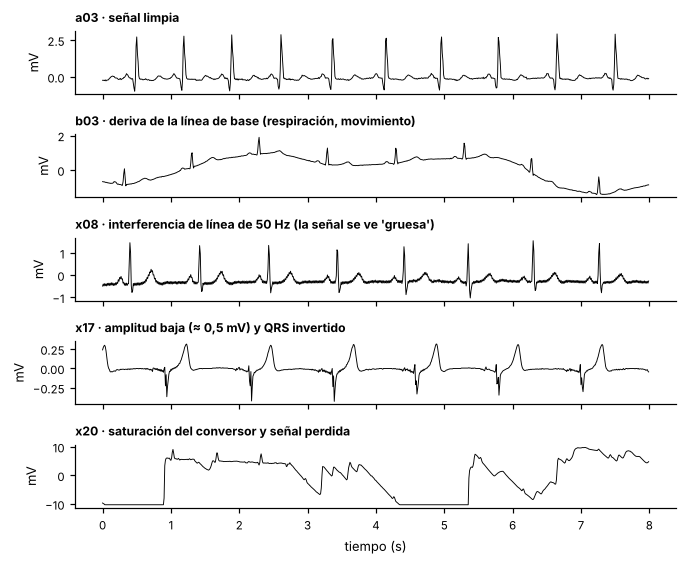

In [10]:
def ventana(rec, t0, dur=8):
    ecg, fs = load_ecg(rec)
    i = int(t0 * fs)
    return np.arange(int(dur * fs)) / fs, ecg[i:i + int(dur * fs)]

ejemplos = [
    ("a03", 3600, "a03 · señal limpia"),
    ("b03", 3*3600 + 600, "b03 · deriva de la línea de base (respiración, movimiento)"),
    ("x08", 2*3600, "x08 · interferencia de línea de 50 Hz (la señal se ve 'gruesa')"),
    ("x17", 2*3600, "x17 · amplitud baja (≈ 0,5 mV) y QRS invertido"),
    ("x20", 163.17 * 60 - 4, "x20 · saturación del conversor y señal perdida"),
]
fig, axs = plt.subplots(len(ejemplos), 1, figsize=(ANCHO, 5.2), sharex=True)
for ax, (rec, t0, titulo) in zip(axs, ejemplos):
    t, x = ventana(rec, t0)
    ax.plot(t, x, color="black", lw=0.6)
    ax.set_title(titulo, fontsize=8)
    ax.set_ylabel("mV")
axs[-1].set_xlabel("tiempo (s)")
fig.tight_layout()
save(fig, "01_ejemplos_ecg")

**Qué se ve.**
- **a03**: los complejos QRS se distinguen con claridad; las ondas P y T también.
- **b03**: el nivel de la señal sube y baja lentamente (deriva de la línea de base). Mueve la amplitud aparente de cada latido y molesta para medir el QRS.
- **x08**: hay una oscilación rápida superpuesta a todo el registro. A 100 Hz de muestreo, la frecuencia de Nyquist es justo 50 Hz, la frecuencia de la red eléctrica en Alemania, donde se grabó la base: la interferencia aparece como una alternancia muestra a muestra.
- **x17**: el QRS mide ~0,5 mV pico a pico y apunta hacia abajo (la polaridad depende de dónde quedaron los electrodos). El detector de latidos tiene que funcionar con las dos polaridades y con amplitudes chicas.
- **x20**: la señal toca el tope del conversor (−10 mV) y queda plana: electrodo despegado o movimiento. En esos tramos no hay latidos que detectar.

Los mismos problemas se ven en frecuencia, y ahí se pueden medir en todos los registros.

## 5. Las señales en frecuencia

Se calcula la densidad espectral de potencia (PSD) de cada registro de desarrollo con el método de Welch (segmentos de 4096 muestras, ≈ 41 s, resolución de 0,024 Hz), normalizada a potencia total 1 para que todos los registros pesen igual. También se calcula el espectro del **latido** mediano de cada registro (de −250 a +400 ms alrededor de cada marca de QRS): es la parte de la señal que interesa conservar.

In [11]:
psds, beats, filas = [], [], []
for rec in DEV:
    ecg, fs = load_ecg(rec)
    d = load_ecg_digital(rec); h = load_header(rec)
    f, p = welch(ecg - ecg.mean(), fs=fs, nperseg=4096)
    p = p / np.trapezoid(p, f)
    qrs = load_qrs(rec)
    _, rr, corr = clean_rr(qrs / fs)
    banda = lambda a, b: float(np.trapezoid(p[(f >= a) & (f < b)], f[(f >= a) & (f < b)]))
    alt = (ecg[:-1:2] - ecg[1::2]) / 2                   # componente que alterna muestra a muestra (50 Hz)
    perdida = flat_mask(d, fs) | saturated_mask(d - h["cero"], h["bits"])
    filas.append({"record": rec, "pot_bajo_0.5Hz": banda(0, 0.5), "pot_40_50Hz": banda(40, 50.01),
                  "pico_50Hz": float(p[-1] / np.median(p[(f > 45) & (f < 49)])),
                  "amplitud_mV": float(np.percentile(ecg, 99) - np.percentile(ecg, 1)),
                  "senal_perdida_pct": 100 * float(perdida.mean()),
                  "rr_corregidos_pct": 100 * float(corr.mean()),
                  "fc_lpm": 60 / float(np.median(rr))})
    if True:
        psds.append(p)
        a, b = 25, 40
        pk = qrs[(qrs > a) & (qrs < len(ecg) - b)]
        beat = np.median(ecg[pk[:, None] + np.arange(-a, b)], axis=0)
        beat = beat - np.median(beat)
        fb = np.fft.rfftfreq(1024, 1 / fs)
        pb = np.abs(np.fft.rfft(beat, 1024)) ** 2
        beats.append(pb / np.trapezoid(pb, fb))
        filas[-1]["f99_latido_Hz"] = float(fb[np.searchsorted(np.cumsum(pb) / pb.sum(), 0.99)])
psds, beats = np.array(psds), np.array(beats)
calidad = pd.DataFrame(filas).merge(split[["record", "set", "category"]])

PosixPath('/home/user/TP-PSB-G8/informe/figuras/01_espectro_ecg.png')

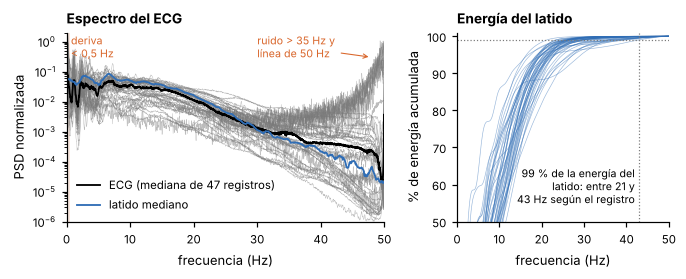

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(ANCHO, 2.6), gridspec_kw={"width_ratios": [1.5, 1]})
for p in psds:
    ax[0].semilogy(f, p, color=GRIS, lw=0.3, alpha=0.5)
ax[0].semilogy(f, np.median(psds, axis=0), color="black", lw=1.2, label="ECG (mediana de 47 registros)")
ax[0].semilogy(fb, np.median(beats, axis=0), color=NORMAL, lw=1.2, label="latido mediano")
ax[0].axvspan(0, 0.5, color=APNEA, alpha=0.15, lw=0)
ax[0].text(0.7, 3e-1, "deriva\n< 0,5 Hz", fontsize=7, color=APNEA)
ax[0].annotate("ruido > 35 Hz y\nlínea de 50 Hz", xy=(48, 3e-1), xytext=(30, 3e-1),
               fontsize=7, color=APNEA, arrowprops=dict(arrowstyle="->", color=APNEA, lw=0.7))
ax[0].set(xlabel="frecuencia (Hz)", ylabel="PSD normalizada", title="Espectro del ECG", xlim=(0, 50),
          ylim=(1e-6, 2))
ax[0].legend(loc="lower left")
for pb in beats:
    c = np.cumsum(pb); ax[1].plot(fb, 100 * c / c[-1], color=NORMAL, lw=0.4, alpha=0.5)
f99 = calidad["f99_latido_Hz"]
ax[1].axhline(99, color=GRIS, ls=":", lw=0.8); ax[1].axvline(f99.max(), color=GRIS, ls=":", lw=0.8)
ax[1].text(f99.max() - 1, 55, f"99 % de la energía del\nlatido: entre {f99.min():.0f} y\n{f99.max():.0f} Hz según el registro",
           fontsize=7, ha="right")
ax[1].set_ylim(50, 101)
ax[1].set(xlabel="frecuencia (Hz)", ylabel="% de energía acumulada", title="Energía del latido", xlim=(0, 50))
fig.tight_layout()
save(fig, "01_espectro_ecg")

**Qué se ve.**
- Por debajo de 0,5 Hz hay mucha potencia que no pertenece al latido (el latido mediano casi no tiene energía ahí): es la **deriva de la línea de base**.
- La energía del latido está entre ~1 y ~40 Hz. A la derecha, la energía acumulada del latido de cada registro: el 99 % queda por debajo de una frecuencia que va de 21 a 43 Hz según el registro.
- En varios registros la potencia vuelve a subir por encima de ~35 Hz y hay un **pico** en el último punto del espectro (50 Hz): ruido de alta frecuencia e interferencia de la red. Como cae justo en Nyquist, no se puede separar del latido con un filtro angosto (notch) sin dañar la señal cerca de 50 Hz, pero sí con un pasabajos por debajo de esa frecuencia, porque el latido casi no tiene energía arriba de 40 Hz.

El espectro tiene la **misma forma en todos los registros** (curvas grises): cambia cuánto pesan la deriva y la interferencia, no dónde están. Eso justifica aplicar el **mismo filtro a todos los registros**. Cuánto pesa cada problema en cada registro se mide abajo.

registros con >10 % de potencia bajo 0,5 Hz         20
registros con pico de 50 Hz (>10 veces el fondo)    23
registros con >1 % de señal perdida                  7
registros con >10 % de RR corregidos                 2
registros                                           47
dtype: int64

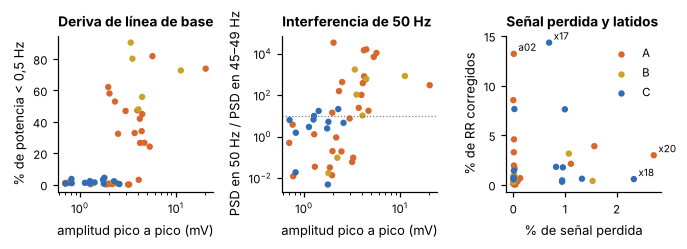

In [13]:
fig, axs = plt.subplots(1, 3, figsize=(ANCHO, 2.3))
orden = calidad.sort_values("category")
colores = orden.category.map(COLORES_CAT)
axs[0].scatter(orden.amplitud_mV, 100 * orden["pot_bajo_0.5Hz"], s=10, c=colores)
axs[0].set(xscale="log", xlabel="amplitud pico a pico (mV)", ylabel="% de potencia < 0,5 Hz",
           title="Deriva de línea de base")
axs[1].scatter(orden.amplitud_mV, orden["pico_50Hz"], s=10, c=colores)
axs[1].set(xscale="log", yscale="log", xlabel="amplitud pico a pico (mV)",
           ylabel="PSD en 50 Hz / PSD en 45–49 Hz", title="Interferencia de 50 Hz")
axs[1].axhline(10, color=GRIS, ls=":", lw=0.8)
axs[2].scatter(orden.senal_perdida_pct, orden.rr_corregidos_pct, s=10, c=colores)
axs[2].set(xlabel="% de señal perdida", ylabel="% de RR corregidos", title="Señal perdida y latidos")
for _, r in orden[(orden.rr_corregidos_pct > 10) | (orden.senal_perdida_pct > 2)].iterrows():
    axs[2].annotate(r.record, (r.senal_perdida_pct, r.rr_corregidos_pct), fontsize=6.5,
                    xytext=(3, 2), textcoords="offset points")
for cat in "ABC":
    axs[2].scatter([], [], s=10, color=COLORES_CAT[cat], label=cat)
axs[2].legend(loc="upper right")
fig.tight_layout()
save(fig, "01_calidad")
resumen = pd.Series({
    "registros con >10 % de potencia bajo 0,5 Hz": int((calidad["pot_bajo_0.5Hz"] > 0.10).sum()),
    "registros con pico de 50 Hz (>10 veces el fondo)": int((calidad["pico_50Hz"] > 10).sum()),
    "registros con >1 % de señal perdida": int((calidad.senal_perdida_pct > 1).sum()),
    "registros con >10 % de RR corregidos": int((calidad.rr_corregidos_pct > 10).sum()),
    "registros": len(calidad),
})
resumen

**Qué se ve.** La deriva y la interferencia de 50 Hz son frecuentes, no casos aislados: 20 de los 47 registros tienen más del 10 % de su potencia por debajo de 0,5 Hz y 23 tienen un pico en 50 Hz. La deriva fuerte aparece en los registros de mayor amplitud. La señal perdida es poca (menos del 3 % de cada registro) y suele aparecer al final de la noche, cuando se retiran los electrodos. Con las marcas de QRS de la base, algunos registros tienen muchos RR corregidos (`a02` y `x17`, más del 10 %; `x25`, `c03` y `x04`, alrededor del 8 %). En `02` se ve por qué: en unos la base pierde latidos y en otros el ritmo cambia de golpe.

### Recorrido de todos los registros

Las figuras anteriores muestran casos. Para no depender de ejemplos elegidos, se mide lo mismo en **cada registro de desarrollo** y, minuto a minuto, **dónde aparecen los problemas en la noche**. Se marcan tres tipos de minuto, con criterios que no dependen de ningún detector:

- **Señal perdida**: tiene un tramo plano o en el tope del conversor de 1 s o más.
- **Sin ECG**: la energía en la banda del QRS (5–15 Hz) es menor al 10 % de la de un minuto típico del mismo registro.
- **Movimiento**: la varianza por debajo de 0,5 Hz es más de 10 veces la de un minuto típico del registro (cambios bruscos de la línea de base).

minutos con cada problema: {'movimiento': 1294, 'sin ECG': 75, 'señal perdida': 191} de 23110
registros con QRS invertido: ['a10', 'a12', 'x05', 'b02', 'c02', 'x17', 'x34']


,cat.,horas,amplitud (mV),FC (lpm),polaridad QRS,"% pot. < 0,5 Hz",50 Hz (× fondo),% señal perdida,% RR corr. (base),min_movimiento,min_sin_ECG,min_perdidos
record,,,,,,,,,,,,
a01,A,8.2,1.96,60.00,+,0.0,0.01,0.02,0.94,0,0,0
a02,A,8.8,0.77,81.08,+,2.0,0.01,0.01,13.20,17,0,0
a03,A,8.7,3.18,67.42,+,0.0,0.06,0.01,1.95,0,0,1
a04,A,8.3,2.46,62.50,+,1.0,0.19,0.03,0.62,56,0,0
a05,A,7.6,4.40,63.16,+,34.0,578.84,0.02,0.21,76,0,4
a08,A,8.3,4.70,82.19,+,27.0,17.71,0.00,0.45,142,0,1
a09,A,8.3,1.30,63.40,+,0.0,0.04,0.01,0.42,0,0,0
a10,A,8.6,2.50,62.50,−,32.0,431.85,0.01,0.16,40,0,5
a12,A,9.6,0.70,61.22,−,1.0,0.50,0.01,4.58,23,0,1


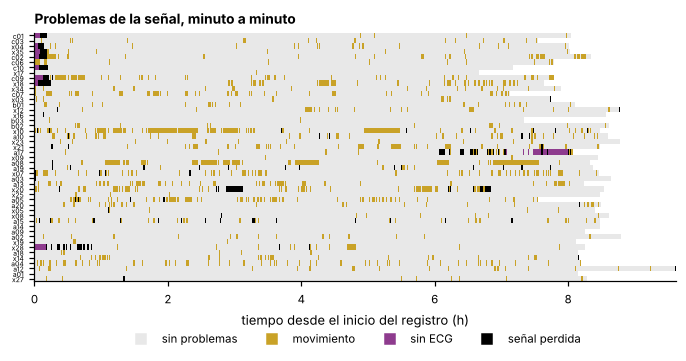

In [14]:
from scipy.signal import butter, sosfiltfilt

def minutos_problema(rec):
    ecg, fs = load_ecg(rec)
    d = load_ecg_digital(rec); h = load_header(rec)
    spm = int(60 * fs); n = min(len(etiq[rec]), len(ecg) // spm)
    perdida = (flat_mask(d, fs) | saturated_mask(d - h["cero"], h["bits"]))[:n * spm].reshape(n, spm).any(1)
    qb = sosfiltfilt(butter(2, [5, 15], "band", fs=fs, output="sos"), ecg)[:n * spm].reshape(n, spm)
    eq = (qb ** 2).mean(1)
    lento = sosfiltfilt(butter(2, 0.5, "low", fs=fs, output="sos"), ecg)[:n * spm].reshape(n, spm).var(1)
    clase = np.zeros(n)
    clase[lento > 10 * np.median(lento)] = 1           # movimiento
    clase[eq < 0.1 * np.median(eq)] = 2                 # sin ECG
    clase[perdida] = 3                                  # señal perdida
    return rec, clase

with ProcessPoolExecutor(4) as ex:
    prob = dict(ex.map(minutos_problema, DEV))
mapa_p = np.full((len(DEV), largo), np.nan)
for i, rec in enumerate(orden_rec):
    mapa_p[i, :len(prob[rec])] = prob[rec]
fig, ax = plt.subplots(figsize=(ANCHO, 3.4))
cm = plt.matplotlib.colors.ListedColormap(["#E8E8E8", "#C9A227", "#8E3B8E", "black"])
ax.imshow(mapa_p, aspect="auto", interpolation="nearest", cmap=cm, vmin=-0.5, vmax=3.5,
          extent=[0, largo / 60, len(DEV), 0])
ax.set_yticks(np.arange(len(DEV)) + 0.5); ax.set_yticklabels(orden_rec, fontsize=4.5)
ax.set(xlabel="tiempo desde el inicio del registro (h)", title="Problemas de la señal, minuto a minuto")
for c, nombre in zip(cm.colors, ["sin problemas", "movimiento", "sin ECG", "señal perdida"]):
    ax.plot([], [], "s", color=c, label=nombre)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=4)
fig.tight_layout()
save(fig, "01_problemas_noche")

# Tabla por registro
for rec in DEV:
    ecg, fs = load_ecg(rec)
    calidad.loc[calidad.record == rec, "polaridad QRS"] = "+" if qrs_reference(ecg, load_qrs(rec), fs)[1] > 0 else "−"
    calidad.loc[calidad.record == rec, "horas"] = round(len(ecg) / fs / 3600, 1)
for nombre, k in (("min_movimiento", 1), ("min_sin_ECG", 2), ("min_perdidos", 3)):
    calidad[nombre] = calidad.record.map(lambda r: int((prob[r] == k).sum()))
tabla_rec = (calidad.set_index("record")
             [["category", "horas", "amplitud_mV", "fc_lpm", "polaridad QRS", "pot_bajo_0.5Hz", "pico_50Hz",
               "senal_perdida_pct", "rr_corregidos_pct", "min_movimiento", "min_sin_ECG", "min_perdidos"]]
             .assign(**{"pot_bajo_0.5Hz": lambda t: (100 * t["pot_bajo_0.5Hz"]).round(0)})
             .rename(columns={"category": "cat.", "amplitud_mV": "amplitud (mV)", "fc_lpm": "FC (lpm)",
                              "pot_bajo_0.5Hz": "% pot. < 0,5 Hz", "pico_50Hz": "50 Hz (× fondo)",
                              "senal_perdida_pct": "% señal perdida", "rr_corregidos_pct": "% RR corr. (base)"})
             .sort_values(["cat.", "record"]))
print("minutos con cada problema:", {n: int(sum((v == k).sum() for v in prob.values()))
                                     for n, k in (("movimiento", 1), ("sin ECG", 2), ("señal perdida", 3))},
      "de", int(sum(len(v) for v in prob.values())))
print("registros con QRS invertido:", list(tabla_rec.index[tabla_rec["polaridad QRS"] == "−"]))
tabla_rec.round(2)

**Qué se ve.**
- La señal perdida y los minutos sin ECG se concentran en **los primeros minutos del registro** (hasta ~15 min), antes de que la señal se estabilice, y sobre todo en los controles (las filas de arriba, ordenadas por cantidad de apnea). Durante la noche aparecen solo en unos pocos registros (`x20`, `a17`, `a15`). El movimiento aparece en cualquier momento, en general en tramos cortos, aunque en algunos registros (`x10`, `a08`) dura decenas de minutos.
- Ningún registro está dañado entero: en todos la mayor parte de la noche no tiene problemas. Por eso no se descarta ningún registro completo, sino **minutos**: los que no tienen latidos confiables se excluyen con la regla de RR corregidos (`02`).
- La tabla resume cada registro. Hay registros con el **QRS invertido** (la polaridad depende de dónde quedaron los electrodos): el detector de latidos y la respiración derivada del ECG tienen que funcionar con las dos polaridades.

### La noche entera de un registro

El espectrograma muestra cómo cambia el espectro a lo largo de la noche. Se calcula con ventanas de 30 s (resolución de 0,033 Hz). Abajo, la franja con las etiquetas de cada minuto.

PosixPath('/home/user/TP-PSB-G8/informe/figuras/01_espectrograma_ecg.png')

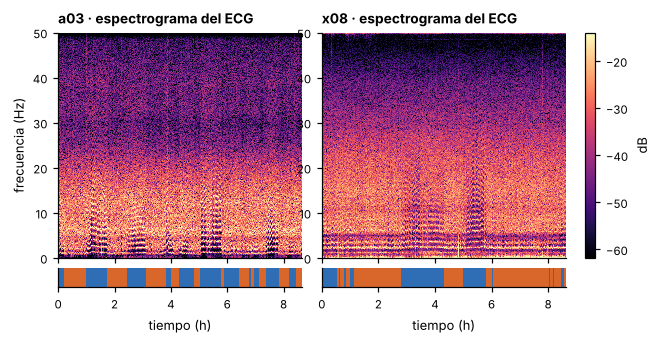

In [15]:
fig, axs = plt.subplots(2, 3, figsize=(ANCHO, 3.0), sharex="col",
                        gridspec_kw={"height_ratios": [6, 0.5], "width_ratios": [1, 1, 0.04],
                                     "hspace": 0.08, "wspace": 0.12})
for j, rec in enumerate(["a03", "x08"]):
    ecg, fs = load_ecg(rec)
    fe, te, S = spectrogram(ecg - ecg.mean(), fs=fs, nperseg=3000, noverlap=1500)
    im = axs[0, j].pcolormesh(te / 3600, fe, 10 * np.log10(S + 1e-12), shading="auto", cmap="magma",
                              vmin=np.percentile(10 * np.log10(S + 1e-12), 5),
                              vmax=np.percentile(10 * np.log10(S + 1e-12), 99.5), rasterized=True)
    axs[0, j].set(title=f"{rec} · espectrograma del ECG", ylabel="frecuencia (Hz)" if j == 0 else None)
    label_strip(axs[1, j], load_apnea_labels(rec), unit=60)
    axs[1, j].set_xlabel("tiempo (h)")
fig.colorbar(im, cax=axs[0, 2], label="dB")
axs[1, 2].axis("off")
save(fig, "01_espectrograma_ecg")

**Qué se ve.**
- En los dos registros la energía está entre ~1 y 40 Hz toda la noche; las franjas verticales breves son movimientos. En `x08` se ve además la línea de 50 Hz en el borde superior.
- En los tramos **normales** (azul) aparecen **líneas horizontales finas y paralelas**: son los armónicos de la frecuencia cardíaca (el ECG es casi periódico). Son nítidas porque la frecuencia cardíaca se mantiene estable durante minutos.
- Durante la **apnea** (naranja) esas líneas se borronean: la frecuencia cardíaca cambia de un latido a otro, con cada ciclo de apnea, y sus armónicos se desparraman.

Es decir, la apnea casi no cambia la forma de cada latido, pero sí **cómo varía el ritmo a lo largo del tiempo**. Para medirlo directamente hay que pasar del ECG a series latido a latido: el intervalo RR y el área del QRS.

## 6. Qué cambia con la apnea

Se comparan 5 minutos con apnea y 5 minutos normales del mismo registro (`a03`), con la respiración medida como referencia. Para cada latido (marcas de QRS de la base) se calculan el intervalo RR y el **área del QRS** (área con signo en ±60 ms alrededor del pico, sobre el ECG filtrado). El área cambia con la respiración porque el tórax se llena y se vacía y el eje eléctrico del corazón se mueve respecto de los electrodos; en `03` se explica y se valida contra la respiración medida.

PosixPath('/home/user/TP-PSB-G8/informe/figuras/01_apnea_vs_normal.png')

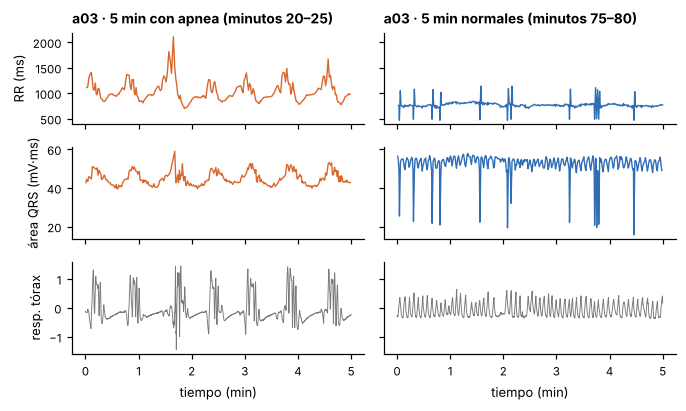

In [16]:
rec = "a03"
ecg, fs = load_ecg(rec)
qrs = load_qrs(rec)
resp, fs_r = load_respiration(rec)
lab = load_apnea_labels(rec)
t_edr, area = compute_edr(ecg, qrs, fs, "area")   # área del QRS de cada latido (ver 03)
t_q = qrs / fs

fig, axs = plt.subplots(3, 2, figsize=(ANCHO, 3.8), sharex="col", sharey="row")
for j, (m0, titulo, color) in enumerate([(20, "5 min con apnea", APNEA), (75, "5 min normales", NORMAL)]):
    sel = (t_q >= 60 * m0) & (t_q < 60 * (m0 + 5))
    tt = t_q[sel] / 60 - m0
    axs[0, j].plot(tt[1:], 1000 * np.diff(t_q[sel]), color=color)
    se = (t_edr >= 60 * m0) & (t_edr < 60 * (m0 + 5))
    axs[1, j].plot(t_edr[se] / 60 - m0, 1000 * area[se], color=color)
    i0, i1 = int(60 * m0 * fs_r), int(60 * (m0 + 5) * fs_r)
    axs[2, j].plot(np.arange(i1 - i0) / fs_r / 60, resp["Resp C"][i0:i1], color=GRIS, lw=0.6)
    axs[0, j].set_title(f"{rec} · {titulo} (minutos {m0}–{m0 + 5})")
    axs[2, j].set_xlabel("tiempo (min)")
axs[0, 0].set_ylabel("RR (ms)"); axs[1, 0].set_ylabel("área QRS (mV·ms)"); axs[2, 0].set_ylabel("resp. tórax")
fig.tight_layout()
save(fig, "01_apnea_vs_normal")

**Qué se ve.**
- **Durante la apnea** la respiración se interrumpe y se reanuda cada ~30–60 s. Con cada ciclo, el RR sube (la frecuencia cardíaca baja durante la pausa) y baja bruscamente cuando se reanuda la respiración: es la **variación cíclica de la frecuencia cardíaca** descripta por Guilleminault et al. (1984). El área del QRS también oscila con el mismo ritmo: sube y baja junto con la respiración, que se detiene y se reanuda.
- **En los minutos normales** el RR y el área del QRS oscilan con la respiración (~4 s por ciclo, 0,25 Hz) y no hay una oscilación lenta compartida. Los picos aislados son latidos ectópicos: en el RR dejan un intervalo corto seguido de uno largo y en el área un valle, porque el latido tiene otra forma. Se corrigen en `02` y `03`.

Entonces la apnea deja una **oscilación lenta, de período entre ~20 y 100 s (0,01–0,05 Hz), común a la serie RR y a la amplitud del QRS**. La serie RR se obtiene detectando los latidos (`02`); la amplitud o el área del QRS a lo largo del tiempo es la respiración derivada del ECG, EDR (`03`). En `04` se mide esa oscilación compartida en todos los minutos.

## 7. En todos los registros: el espectro con y sin apnea

La figura anterior es un solo caso. ¿Pasa lo mismo en todos los registros, y **en qué frecuencias**? Para responderlo se calcula, en cada minuto, el espectro de la serie RR, el de la EDR y el espectro cruzado entre las dos, y se comparan los minutos con apnea con los normales **dentro de cada registro** (así no influye que una persona tenga más variabilidad que otra).

Cómo se calcula (adelanta pasos de `02` y `03`):
- RR con el detector propio y su limpieza (`02`); EDR por área del QRS (`03`). Las dos se interpolan a una grilla común de 2 Hz, porque el espectro cruzado necesita las dos señales muestreadas en los mismos instantes; 2 Hz alcanza para todo lo que está por debajo de 1 Hz, que incluye la respiración (≤ 0,4 Hz).
- Para cada minuto, una ventana de **240 s centrada** en él. Para ver oscilaciones de 0,01 Hz (un ciclo cada 100 s) cada segmento del estimador tiene que durar más de 100 s: se usa el método de Welch con 3 segmentos de 120 s (ventana de Hann, 50 % de solapamiento), que ocupan 240 s. La resolución es de 1/120 s ≈ 0,008 Hz.
- Solo minutos con 20 % o menos de RR corregidos, y registros con al menos 20 minutos de cada tipo.
- En cada registro se promedia el logaritmo del espectro de los minutos con apnea y el de los normales; la diferencia, en decibeles, dice cuánto más potencia hay durante la apnea en cada frecuencia.

31 registros con al menos 20 minutos de cada tipo


,pico (Hz),período del pico (s),dB en el pico,banda a −3 dB del pico (Hz),"registros con más potencia en 0,017–0,05 Hz"
señal,,,,,
serie RR,0.025,40.0,8.224,0.017–0.050,31 de 31
EDR,0.025,40.0,5.277,0.017–0.075,28 de 31
espectro cruzado RR–EDR,0.025,40.0,7.531,0.017–0.042,30 de 31


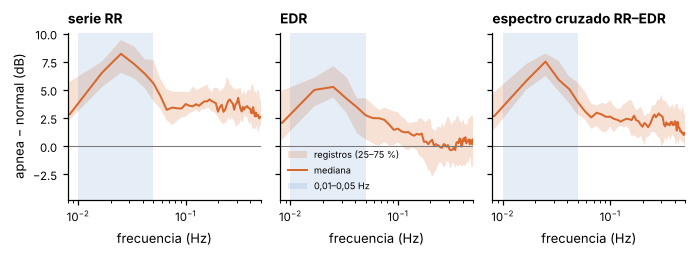

In [17]:
from src.features.build import record_series
from src.features.coupling import welch_spectra
from src.features.windows import centered_windows
from src.qrs.rr_clean import minute_quality

ANCHO_VENTANA, FS_U = 240, 2.0

def espectros_por_clase(rec):
    s = record_series(rec)
    lab = load_apnea_labels(rec)
    q = minute_quality(s["t_rr"], s["corrected"], len(lab))
    minutos, inicios = centered_windows(len(lab), ANCHO_VENTANA, s["t"][0], s["t"][-1] + 1 / FS_U)
    n = int(ANCHO_VENTANA * FS_U)
    out = {0: [], 1: []}
    for m, a in zip(minutos, inicios):
        if lab[m] < 0 or not q[m] <= 0.2:
            continue
        i = int(round((a - s["t"][0]) * FS_U))
        x, y = s["rr"][i:i + n], s["edr"][i:i + n]
        if len(x) < n:
            continue
        f, sxx, syy, sxy = welch_spectra(x, y, FS_U, n // 2)
        out[int(lab[m])].append(np.log10(np.c_[sxx, syy, np.abs(sxy)]))
    return rec, f, {k: np.array(v) for k, v in out.items()}

with ProcessPoolExecutor(4) as ex:
    esp = list(ex.map(espectros_por_clase, DEV))
f_esp = esp[0][1]
usados = [(rec, 10 * (d[1].mean(0) - d[0].mean(0))) for rec, _, d in esp if len(d[0]) >= 20 and len(d[1]) >= 20]
D = np.array([v for _, v in usados])                       # registro × frecuencia × (RR, EDR, cruzado)
med = np.median(D, axis=0)
q25, q75 = np.percentile(D, 25, axis=0), np.percentile(D, 75, axis=0)

nombres = ["serie RR", "EDR", "espectro cruzado RR–EDR"]
fig, axs = plt.subplots(1, 3, figsize=(ANCHO, 2.4), sharey=True)
filas_banda = []
for j, (ax, nombre) in enumerate(zip(axs, nombres)):
    ax.fill_between(f_esp, q25[:, j], q75[:, j], color=APNEA, alpha=0.2, lw=0, label="registros (25–75 %)")
    ax.plot(f_esp, med[:, j], color=APNEA, lw=1.3, label="mediana")
    ax.axhline(0, color=GRIS, lw=0.7)
    ax.axvspan(0.01, 0.05, color=NORMAL, alpha=0.12, lw=0, label="0,01–0,05 Hz")
    pico = int(np.argmax(med[1:, j])) + 1                  # sin la frecuencia cero
    lo_, hi_ = pico, pico                                  # tramo contiguo alrededor del pico
    while lo_ > 1 and med[lo_ - 1, j] >= med[pico, j] - 3:
        lo_ -= 1
    while hi_ < len(f_esp) - 1 and med[hi_ + 1, j] >= med[pico, j] - 3:
        hi_ += 1
    grupo = [lo_, hi_]
    filas_banda.append({"señal": nombre, "pico (Hz)": f_esp[pico], "período del pico (s)": 1 / f_esp[pico],
                        "dB en el pico": med[pico, j], "banda a −3 dB del pico (Hz)":
                        f"{f_esp[grupo[0]]:.3f}–{f_esp[grupo[-1]]:.3f}",
                        "registros con más potencia en 0,017–0,05 Hz": f"{int(np.sum(D[:, (f_esp >= 0.016) & (f_esp <= 0.051), j].mean(1) > 0))} de {len(D)}"})
    ax.set(xscale="log", xlim=(0.008, 0.5), xlabel="frecuencia (Hz)", title=nombre)
axs[0].set_ylabel("apnea − normal (dB)")
axs[1].legend(loc="lower left", fontsize=6)
fig.tight_layout()
save(fig, "01_espectro_apnea")
print(f"{len(usados)} registros con al menos 20 minutos de cada tipo")
pd.DataFrame(filas_banda).set_index("señal").round(3)

**Qué se ve.**
- Durante la apnea el RR tiene **más potencia en todas las frecuencias** (la curva está siempre arriba de 0 dB; la EDR, solo por debajo de ~0,2 Hz), pero el aumento es **mucho mayor en una banda lenta**, con el máximo en 0,025 Hz: un ciclo cada ~40 s, el ritmo de una apnea y su recuperación.
- La banda donde el aumento está a menos de 3 dB de su máximo va de ~0,017 a ~0,05 Hz en el RR (períodos de 20 a 60 s). Es la banda de la hipótesis, ahora **medida en los datos** y no supuesta.
- El efecto aparece en el RR, en la EDR y en el espectro cruzado, y en casi todos los registros (última columna). En la EDR es más chico que en el RR; el espectro cruzado mide lo que las dos tienen en común. Cuál de las tres separa mejor los minutos se mide en `04`.

## 8. Qué se lleva el resto del trabajo

| Observación | Consecuencia |
|---|---|
| Hay noches casi enteras de apnea y otras sin apnea; 29 registros tienen los dos tipos de minuto | evaluar también dentro de cada noche (`04`) |
| Los minutos con apnea vienen en tramos (mediana 6 min); los minutos no son independientes | intervalos de confianza por sujeto (`04`); una ventana de algunos minutos no borra la mayoría de los episodios |
| Deriva de línea de base por debajo de 0,5 Hz en muchos registros | pasaaltos que la saque sin tocar el latido (el ritmo cardíaco más lento, ~0,8 Hz) (`02`) |
| Interferencia de 50 Hz en Nyquist; el 99 % de la energía del latido está por debajo de ~40 Hz | pasabajos entre 40 y 50 Hz (`02`) |
| Misma forma espectral en todos los registros | un único filtro para todos (`02`) |
| A 100 Hz el pico R cae en una grilla de 10 ms | refinar la posición del pico (`02`) |
| Amplitudes bajas, QRS invertidos, tramos sin ECG y señal perdida, sobre todo al principio y al final | detector de latidos que funcione con las dos polaridades y no marque latidos donde no hay ECG; excluir minutos, no registros (`02`) |
| La apnea aumenta la potencia del RR y de la EDR, sobre todo entre ~0,017 y 0,05 Hz (ciclos de 20 a 60 s) | feature: potencia compartida por RR y EDR en esa banda, en una ventana de 240 s (`04`) |